<img src="https://www.th-koeln.de/img/logo.svg" style="float:right;" width="200">

# 6th exercise: <font color="#C70039">Work with Autoencoders for anomaly detection</font>
* Course: AML
* Lecturer: <a href="https://www.gernotheisenberg.de/">Gernot Heisenberg</a>
* Author of notebook: <a href="https://www.gernotheisenberg.de/">Gernot Heisenberg</a>
* Date:   10.08.2026

<img src="https://blog.keras.io/img/ae/autoencoder_schema.jpg" style="float: center;" width="700">

---------------------------------
**GENERAL NOTE 1**:
Please make sure you are reading the entire notebook, since it contains a lot of information on your tasks (e.g. regarding the set of certain parameters or a specific computational trick), and the written mark downs as well as comments contain a lot of information on how things work together as a whole.

**GENERAL NOTE 2**:
* Please, when commenting source code, just use English language only.
* When describing an observation please use English language, too.
* This applies to all exercises throughout this course.

---------------------------------

### <font color="ce33ff">DESCRIPTION</font>:
Autoencoder is an unsupervised artificial neural network (ANN) that learns how to efficiently compress and encode data and then learns how to reconstruct the data back from the reduced encoded representation to a representation that is as close to the original input as possible.

An Autoencoder reduces data dimensions by learning how to ignore the noise in the data and thus outliers.
In the section above, you can seen an example of the input/output image from the MNIST dataset to an Autoencoder.

#### Autoencoder Components:
An Autoencoder consists of four main parts:

1. Encoder: In which the model learns how to reduce the input dimensions and compress the input data into an encoded representation.

2. Bottleneck: which is the layer that contains the compressed representation of the input data. This is the lowest possible dimensions of the input data. The bottlneck is also called latent vector. The concept of the latent space and latent vectors becomes important later on as we move forward to understand Generative Models.

3. Decoder: In which the model learns how to reconstruct the data from the encoded representation to be as close to the original input as possible.

4. Reconstruction Loss: This is the method that measures how well the decoder is performing and how close the output is to the original input.

As always in ANNs, the training itself involves back propagation in order to minimize the network’s reconstruction loss.

Due to this features of an Autoencoder the use cases are manyfold. One of the obviously is anomaly detection.

#### Autoencoder Architecture:

The network architecture for Autoencoders can vary between simple Feed Forward networks, Recurrent Neural Networks (LSTM) or Convolutional Neural Networks (CNN) depending on the use case.

---------------------------------

### <font color="FFC300">TASKS</font>:
The tasks that you need to work on within this notebook are always indicated below as bullet points.
If a task is more challenging and consists of several steps, this is indicated as well.
Make sure you have worked down the task list and commented your doings.
This should be done by using markdown.<br>
<font color=red>Make sure you don't forget to specify your name and your matriculation number in the notebook.</font>

**YOUR TASKS in this exercise are as follows**:
1. import the notebook to Google Colab or use your local machine.
2. make sure you specified your name and your matriculation number in the header below my name and date.
    * set the date too and remove mine.
3. read the entire notebook carefully
    * add comments wherever you feel it necessary for better understanding
    * run the notebook for the first time.
    * the example below shows how to use an autoencoder for anomaly detection

4. <font color=green>Develop an Autoencoder for Domain Adaptation (Me -> Walter White ). You can of course also take own data, e.g. a photo of yours and someone else.</font>
5. Use shuffled mini-batches, choose a justified epoch limit, and monitor the reconstruction loss to avoid unnecessary training.
6. Implement a CNN for working out important features for the adaptation. If you feel lost in the exercise, please visit the sample solution.
7. There is also an implementation of data augmentation that helps you building up your data set from one single "original" image.
---------------------------------

### Auto-Encoding
If you have correlated input data, the auto-encoder method will work very well because the encoding operation relies on the correlated features to compress the data.
Let’s consider that an auto-encoder is trained on the MNIST dataset.
As you know already, using a simple FeedForward neural network, this can be done by building a simple 6 layers network as below:

In [ ]:
# Train the network to reconstruct MNIST images, not to predict their digit labels.
# The small bottleneck forces the autoencoder to keep only essential image information.
import numpy as np
import torch
from pathlib import Path
from urllib.request import urlretrieve
from PIL import Image
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets
from torchvision.transforms import functional as TF
from torchvision.transforms import v2

torch.manual_seed(1)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# Load MNIST as normalized tensors in the interval [0, 1].
tensor_transform = v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])
mnist_train = datasets.MNIST(root="./data", train=True, download=True, transform=tensor_transform)
mnist_test = datasets.MNIST(root="./data", train=False, download=True, transform=tensor_transform)
train_loader = DataLoader(mnist_train, batch_size=1_024, shuffle=True)
validation_loader = DataLoader(mnist_test, batch_size=1_024, shuffle=False)


class Autoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 512),
            nn.ELU(),
            nn.Linear(512, 128),
            nn.ELU(),
            nn.Linear(128, 10),
        )
        self.decoder = nn.Sequential(
            nn.Linear(10, 128),
            nn.ELU(),
            nn.Linear(128, 512),
            nn.ELU(),
            nn.Linear(512, 784),
            nn.Sigmoid(),
        )

    def forward(self, inputs):
        return self.decoder(self.encoder(inputs))


autoencoder = Autoencoder().to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(autoencoder.parameters())
history = {"training_loss": [], "validation_loss": []}

for epoch in range(10):
    autoencoder.train()
    training_loss = 0.0
    for images, _ in train_loader:
        images = images.to(device)
        optimizer.zero_grad()
        reconstructions = autoencoder(images)
        loss = criterion(reconstructions, images.flatten(start_dim=1))
        loss.backward()
        optimizer.step()
        training_loss += loss.item() * images.size(0)

    autoencoder.eval()
    validation_loss = 0.0
    with torch.inference_mode():
        for images, _ in validation_loader:
            images = images.to(device)
            reconstructions = autoencoder(images)
            validation_loss += criterion(reconstructions, images.flatten(start_dim=1)).item() * images.size(0)

    training_loss /= len(mnist_train)
    validation_loss /= len(mnist_test)
    history["training_loss"].append(training_loss)
    history["validation_loss"].append(validation_loss)
    print(f"Epoch {epoch + 1:02d}: train={training_loss:.5f}, validation={validation_loss:.5f}")

# The encoder and decoder are available as autoencoder.encoder and autoencoder.decoder.

Using device: cpu
Epoch 01: train=0.08064, validation=0.06062
Epoch 02: train=0.05317, validation=0.04486
Epoch 03: train=0.03870, validation=0.03379
Epoch 04: train=0.03086, validation=0.02766
Epoch 05: train=0.02625, validation=0.02418
Epoch 06: train=0.02364, validation=0.02230
Epoch 07: train=0.02204, validation=0.02101
Epoch 08: train=0.02086, validation=0.02004
Epoch 09: train=0.01996, validation=0.01938
Epoch 10: train=0.01923, validation=0.01863


The validation reconstruction loss should decrease as training progresses. An autoencoder trained only on MNIST digits generally reconstructs in-distribution digits better than unrelated images. For anomaly detection, compare per-image reconstruction errors and derive a threshold from held-out normal data instead of relying on a fixed value from one run.

#### Autoencoders for anomaly detection
The following cells compute the mean squared reconstruction error for a held-out MNIST image and for two external images. All images are normalized to the same `[0, 1]` range before comparison. The 99th percentile of the validation errors is used as a transparent example threshold.

In [ ]:
# Calculate an individual reconstruction error for every image in a batch.
# A validation quantile provides a data-driven example threshold for anomalies.
def reconstruction_errors(images):
    autoencoder.eval()
    images = images.to(device)
    with torch.inference_mode():
        reconstructions = autoencoder(images)
    targets = images.flatten(start_dim=1)
    return torch.mean((targets - reconstructions) ** 2, dim=1).cpu()


# Estimate an anomaly threshold from held-out normal observations.
validation_errors = []
for images, _ in validation_loader:
    validation_errors.append(reconstruction_errors(images))
validation_errors = torch.cat(validation_errors)
anomaly_threshold = torch.quantile(validation_errors, 0.99).item()

input_image, _ = mnist_test[50]
mnist_error = reconstruction_errors(input_image.unsqueeze(0)).item()
print(f"MNIST reconstruction error: {mnist_error:.6f}")
print(f"Example 99th-percentile threshold: {anomaly_threshold:.6f}")

MNIST reconstruction error: 0.007118
Example 99th-percentile threshold: 0.050138


In [ ]:
# Convert external images to the same grayscale size and [0, 1] range as MNIST.
# Only comparable preprocessing makes reconstruction errors meaningful.
DATA_BASE_URL = "https://raw.githubusercontent.com/gheisenberg/AML/main/data"


def exercise_image(filename):
    path = Path("./data") / filename
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        urlretrieve(f"{DATA_BASE_URL}/{filename}", path)
    return path


def load_grayscale_tensor(path):
    image = Image.open(path).convert("L").resize((28, 28))
    return TF.pil_to_tensor(image).float().div(255.0)


yoda_image = load_grayscale_tensor(exercise_image("yoda.png"))
yoda_error = reconstruction_errors(yoda_image.unsqueeze(0)).item()
print(f"Yoda reconstruction error: {yoda_error:.6f}")
print("Anomaly:", yoda_error > anomaly_threshold)

Yoda reconstruction error: 0.082656
Anomaly: True


In [ ]:
# A visually similar digit can still be outside the training distribution.
# Compare its error with the validation threshold rather than a fixed number.
# This digit resembles MNIST, but differences in contrast, centering, or stroke style can still cause distribution shift.
external_digit = load_grayscale_tensor(exercise_image("similarMnistNumber.jpg"))
external_digit_error = reconstruction_errors(external_digit.unsqueeze(0)).item()
print(f"External digit reconstruction error: {external_digit_error:.6f}")
print("Anomaly:", external_digit_error > anomaly_threshold)

External digit reconstruction error: 0.020315
Anomaly: False


## Exercise Solutions: CNN Autoencoder for Domain Adaptation (Source $\rightarrow$ Target)
### Tasks 5, 7, 9 & 11: Data Augmentation, CNN Architecture, Shuffled Mini-Batches & Loss Monitoring
* **Data Augmentation (Task 11):** Starting from one source portrait and one target portrait (`128 x 128` RGB), we generate `600` paired training samples and `100` validation samples using synchronized geometric transforms (random affine rotation/translation/scale) plus independent color/brightness jitter so the CNN learns robust structural facial features rather than memorizing pixel coordinates.
* **CNN Autoencoder Architecture (Task 9):** A symmetric 4-stage Convolutional Encoder (`Conv2d` + `BatchNorm2d` + `LeakyReLU`) compresses the `3 x 128 x 128` input image down to an `8 x 8 x 256` latent bottleneck, and a 4-stage Transposed Convolutional Decoder (`ConvTranspose2d` + `BatchNorm2d` + `ReLU` + `Sigmoid`) reconstructs the `3 x 128 x 128` target domain image.
* **Training & Early Stopping (Task 7):** We train using shuffled mini-batches (`batch_size = 32`, `shuffle = True`), a justified maximum limit of `60` epochs, and **early stopping** (`patience = 8`) that monitors validation reconstruction loss (`MSELoss`) to halt training once convergence is reached.

In [5]:
import random
import matplotlib.pyplot as plt
import torch
from PIL import Image
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision.transforms import functional as TF

# Reproducibility and GPU/CPU device selection
torch.manual_seed(42)
random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Training CNN Autoencoder on device:", device)

# --- 1. Load Source ("Me") and Target ("Walter White") Portrait Images ---
source_pil = Image.open("/content/me.png").convert("RGB").resize((128, 128))
target_pil = (
    Image.open("/content/target.png").convert("RGB").resize((128, 128))
)
print(
    "Successfully loaded /content/me.png and /content/target.png (128x128"
    " RGB)."
)


# --- 2. Task 11: Build Dataset from a Single Image Pair via Data Augmentation ---
def build_augmented_dataset(src_img, tgt_img, n_samples=600):
    """Generates paired source->target tensors using synchronized geometric augmentations."""
    src_list, tgt_list = [], []
    for i in range(n_samples):
        if i == 0:
            # Keep the exact unaugmented original pair as sample 0
            s_aug, t_aug = src_img, tgt_img
        else:
            # Apply identical spatial transformations so facial alignment is preserved
            angle = random.uniform(-15.0, 15.0)
            translate = (random.randint(-8, 8), random.randint(-8, 8))
            scale = random.uniform(0.90, 1.10)
            do_flip = random.random() < 0.5

            s_aug = TF.affine(src_img, angle=angle, translate=translate, scale=scale, shear=0.0)
            t_aug = TF.affine(tgt_img, angle=angle, translate=translate, scale=scale, shear=0.0)
            if do_flip:
                s_aug = TF.hflip(s_aug)
                t_aug = TF.hflip(t_aug)

            # Slight brightness/contrast variation on the input so the encoder generalizes
            s_aug = TF.adjust_brightness(s_aug, random.uniform(0.85, 1.15))
            s_aug = TF.adjust_contrast(s_aug, random.uniform(0.85, 1.15))

        src_list.append(TF.to_tensor(s_aug))
        tgt_list.append(TF.to_tensor(t_aug))

    return TensorDataset(torch.stack(src_list), torch.stack(tgt_list))


train_dataset = build_augmented_dataset(source_pil, target_pil, n_samples=600)
val_dataset = build_augmented_dataset(source_pil, target_pil, n_samples=100)

# Task 7: Shuffled mini-batches for training
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)


# --- 3. Task 9: Convolutional Autoencoder (CNN) for Domain Adaptation ---
class CNNCrossDomainAutoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        # Encoder: compresses (3, 128, 128) -> (256, 8, 8) latent bottleneck
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=4, stride=2, padding=1),   # -> (32, 64, 64)
            nn.BatchNorm2d(32),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(32, 64, kernel_size=4, stride=2, padding=1),  # -> (64, 32, 32)
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1), # -> (128, 16, 16)
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(128, 256, kernel_size=4, stride=2, padding=1),# -> (256, 8, 8)
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2, inplace=True),
        )
        # Decoder: reconstructs (256, 8, 8) -> (3, 128, 128) target domain image
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(256, 128, kernel_size=4, stride=2, padding=1), # -> (128, 16, 16)
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),  # -> (64, 32, 32)
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1),   # -> (32, 64, 64)
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(32, 3, kernel_size=4, stride=2, padding=1),    # -> (3, 128, 128)
            nn.Sigmoid(),  # Scales output pixels to [0, 1]
        )

    def forward(self, x):
        latent = self.encoder(x)
        return self.decoder(latent)


model = CNNCrossDomainAutoencoder().to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

# --- 4. Task 7: Train with Epoch Limit & Early Stopping Loss Monitoring ---
max_epochs = 60
patience = 8
best_val_loss = float("inf")
epochs_without_improvement = 0
best_weights = None

train_losses, val_losses = [], []

for epoch in range(1, max_epochs + 1):
    model.train()
    running_train = 0.0
    for src_batch, tgt_batch in train_loader:
        src_batch, tgt_batch = src_batch.to(device), tgt_batch.to(device)
        optimizer.zero_grad()
        pred_batch = model(src_batch)
        loss = criterion(pred_batch, tgt_batch)
        loss.backward()
        optimizer.step()
        running_train += loss.item() * src_batch.size(0)

    model.eval()
    running_val = 0.0
    with torch.inference_mode():
        for src_batch, tgt_batch in val_loader:
            src_batch, tgt_batch = src_batch.to(device), tgt_batch.to(device)
            pred_batch = model(src_batch)
            running_val += criterion(pred_batch, tgt_batch).item() * src_batch.size(0)

    epoch_train_loss = running_train / len(train_dataset)
    epoch_val_loss = running_val / len(val_dataset)
    train_losses.append(epoch_train_loss)
    val_losses.append(epoch_val_loss)

    if epoch % 5 == 0 or epoch == 1:
        print(f"Epoch {epoch:02d}/{max_epochs} | Train MSE: {epoch_train_loss:.5f} | Val MSE: {epoch_val_loss:.5f}")

    # Monitor validation reconstruction loss for early stopping
    if epoch_val_loss < best_val_loss - 1e-5:
        best_val_loss = epoch_val_loss
        epochs_without_improvement = 0
        best_weights = {k: v.cpu().clone() for k, v in model.state_dict().items()}
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= patience:
            print(f"Early stopping triggered at epoch {epoch} (best Val MSE: {best_val_loss:.5f}).")
            break

# Restore best model weights
if best_weights is not None:
    model.load_state_dict(best_weights)

Training CNN Autoencoder on device: cpu
Successfully loaded /content/me.png and /content/target.png (128x128 RGB).
Epoch 01/60 | Train MSE: 0.07734 | Val MSE: 0.07494
Epoch 05/60 | Train MSE: 0.01879 | Val MSE: 0.03212
Epoch 10/60 | Train MSE: 0.01087 | Val MSE: 0.02521
Epoch 15/60 | Train MSE: 0.00748 | Val MSE: 0.00851
Epoch 20/60 | Train MSE: 0.00613 | Val MSE: 0.00735
Epoch 25/60 | Train MSE: 0.00532 | Val MSE: 0.00640
Epoch 30/60 | Train MSE: 0.00478 | Val MSE: 0.00646
Epoch 35/60 | Train MSE: 0.00440 | Val MSE: 0.00593
Epoch 40/60 | Train MSE: 0.00400 | Val MSE: 0.00564
Epoch 45/60 | Train MSE: 0.00385 | Val MSE: 0.00694
Epoch 50/60 | Train MSE: 0.00350 | Val MSE: 0.00490
Epoch 55/60 | Train MSE: 0.00344 | Val MSE: 0.00488
Epoch 60/60 | Train MSE: 0.00316 | Val MSE: 0.00580


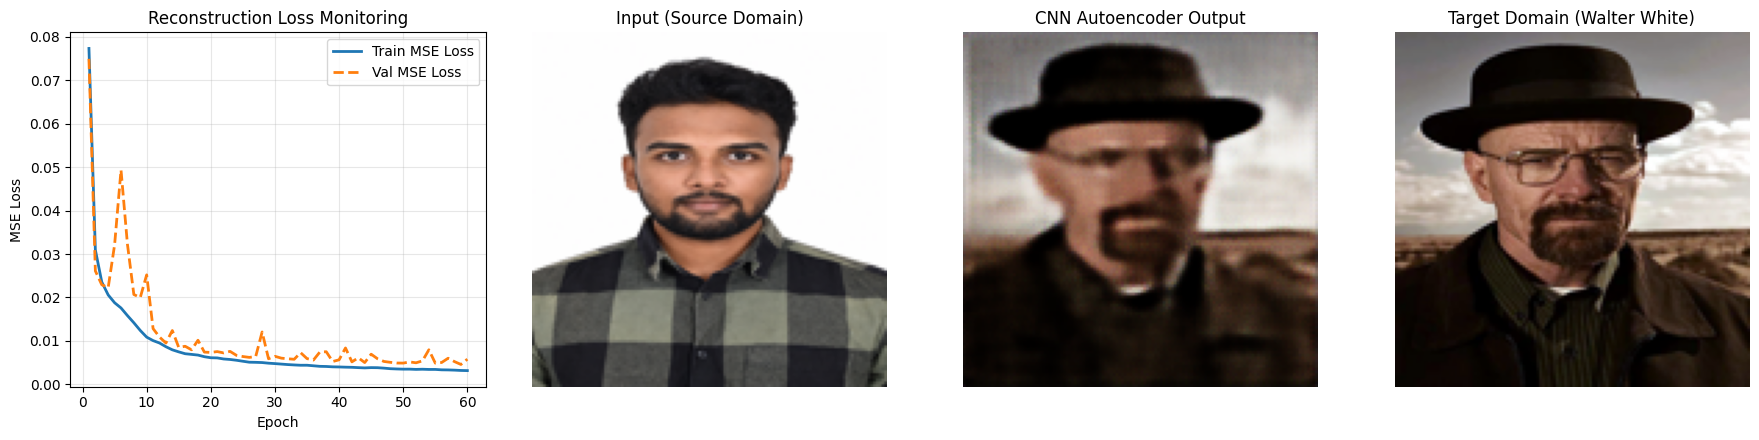

In [6]:
# --- 5. Visualize Reconstruction Loss & Domain Adaptation Output ---
model.eval()
with torch.inference_mode():
    orig_src_tensor = TF.to_tensor(source_pil).unsqueeze(0).to(device)
    adapted_tensor = model(orig_src_tensor).squeeze(0).cpu()

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))

# Plot 1: Reconstruction Loss Curve
axes[0].plot(range(1, len(train_losses) + 1), train_losses, label="Train MSE Loss", linewidth=2)
axes[0].plot(range(1, len(val_losses) + 1), val_losses, label="Val MSE Loss", linestyle="--", linewidth=2)
axes[0].set_title("Reconstruction Loss Monitoring")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MSE Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot 2: Input Source Image
axes[1].imshow(source_pil)
axes[1].set_title("Input (Source Domain)")
axes[1].axis("off")

# Plot 3: CNN Autoencoder Adapted Output
axes[2].imshow(TF.to_pil_image(adapted_tensor.clamp(0, 1)))
axes[2].set_title("CNN Autoencoder Output")
axes[2].axis("off")

# Plot 4: Ground Truth Target Image (Walter White)
axes[3].imshow(target_pil)
axes[3].set_title("Target Domain (Walter White)")
axes[3].axis("off")

plt.tight_layout()
plt.show()